Libraries imported successfully!


100%|██████████| 19.3M/19.3M [00:01<00:00, 18.9MB/s]

Extracting files...


Dataset downloaded successfully!
Dataset location: /root/.cache/kagglehub/datasets/camnugent/sandp500/versions/4
Selected CSV: /root/.cache/kagglehub/datasets/camnugent/sandp500/versions/4/all_stocks_5yr.csv

First five rows:


,date,open,high,low,close,volume,name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL



Dataset shape: (619040, 7)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619040 non-null  object 
 1   open    619029 non-null  float64
 2   high    619032 non-null  float64
 3   low     619032 non-null  float64
 4   close   619040 non-null  float64
 5   volume  619040 non-null  int64  
 6   name    619040 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB

Data cleaning completed!

Missing values:
date      0
open      0
high      0
low       0
close     0
volume    0
name      0
dtype: int64

Selected Company: AAPL
Total observations: 1259
Date range:
2013-02-08 00:00:00 to 2018-02-07 00:00:00


,open,high,low,close,volume
date,,,,,
2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416
2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425
2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363
2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995
2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154


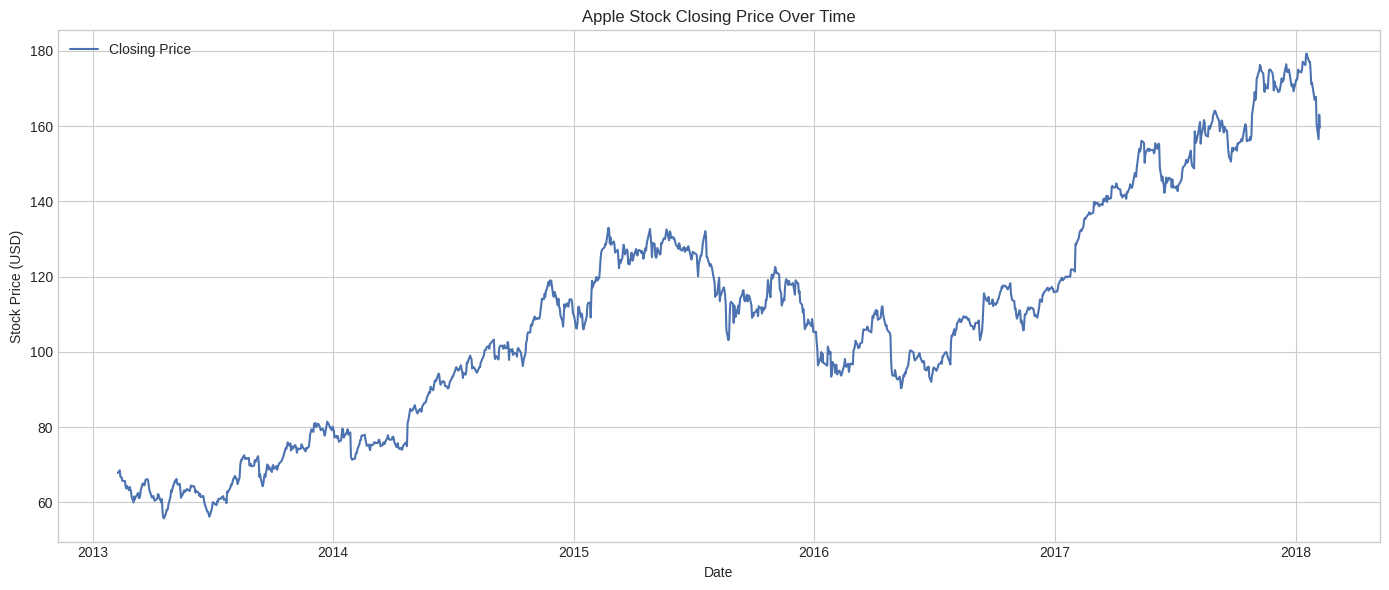

/usr/local/lib/python3.13/dist-packages/mplfinance/_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+


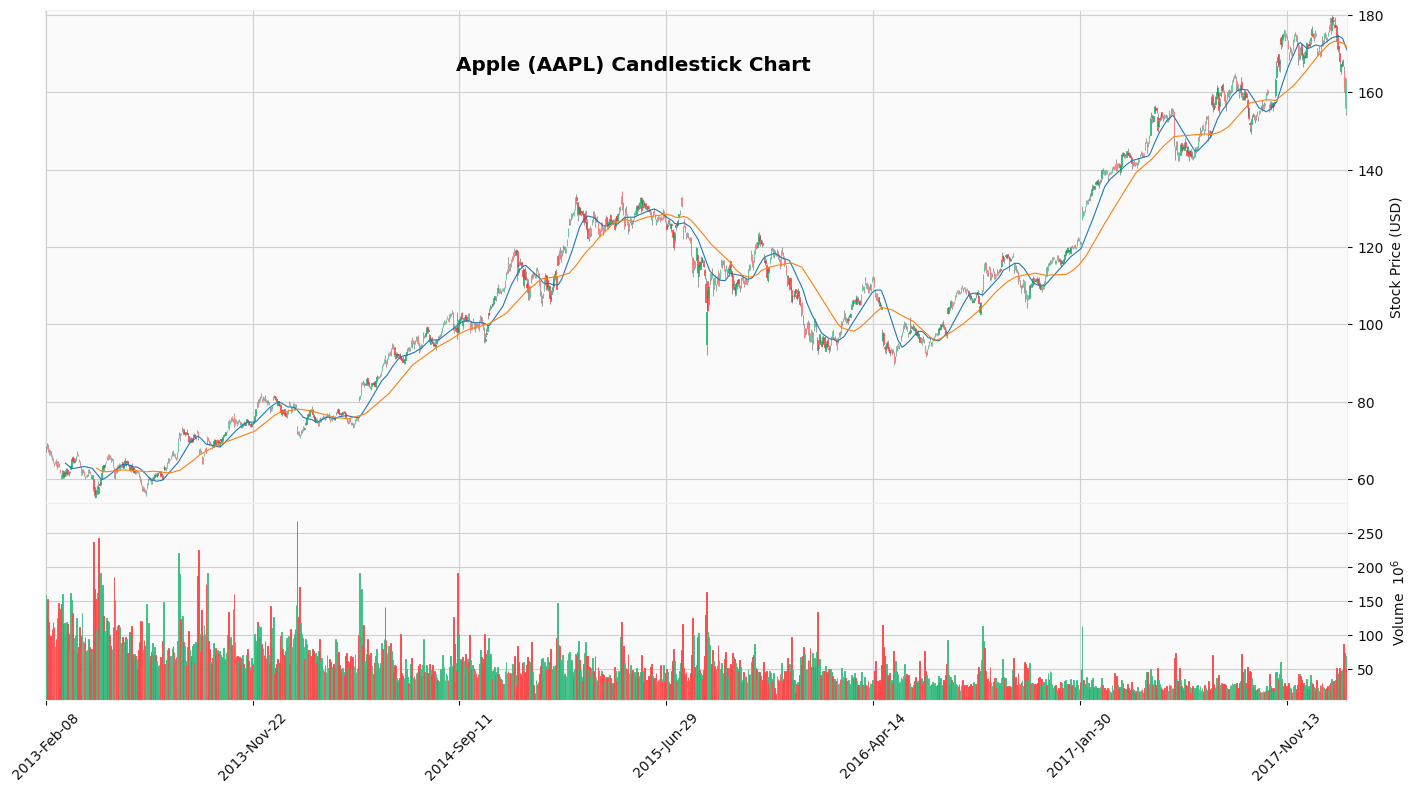

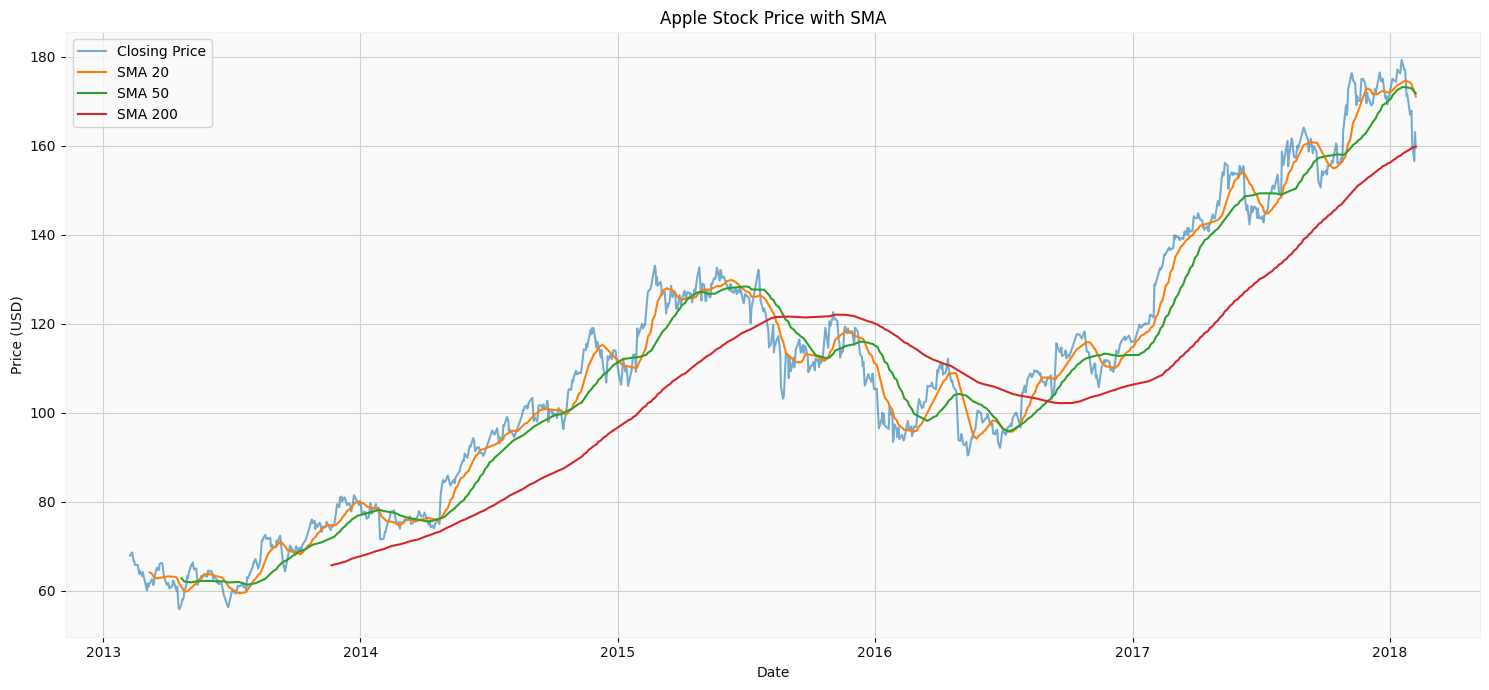

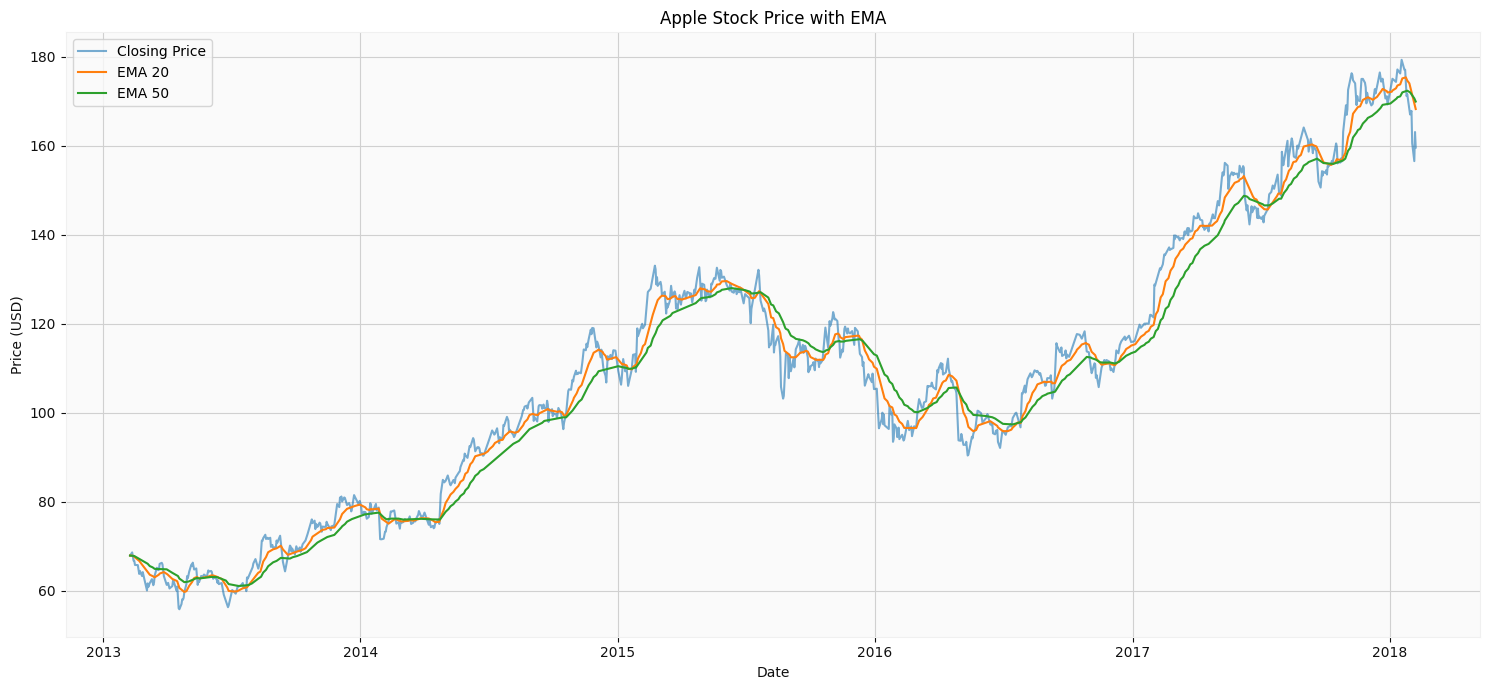

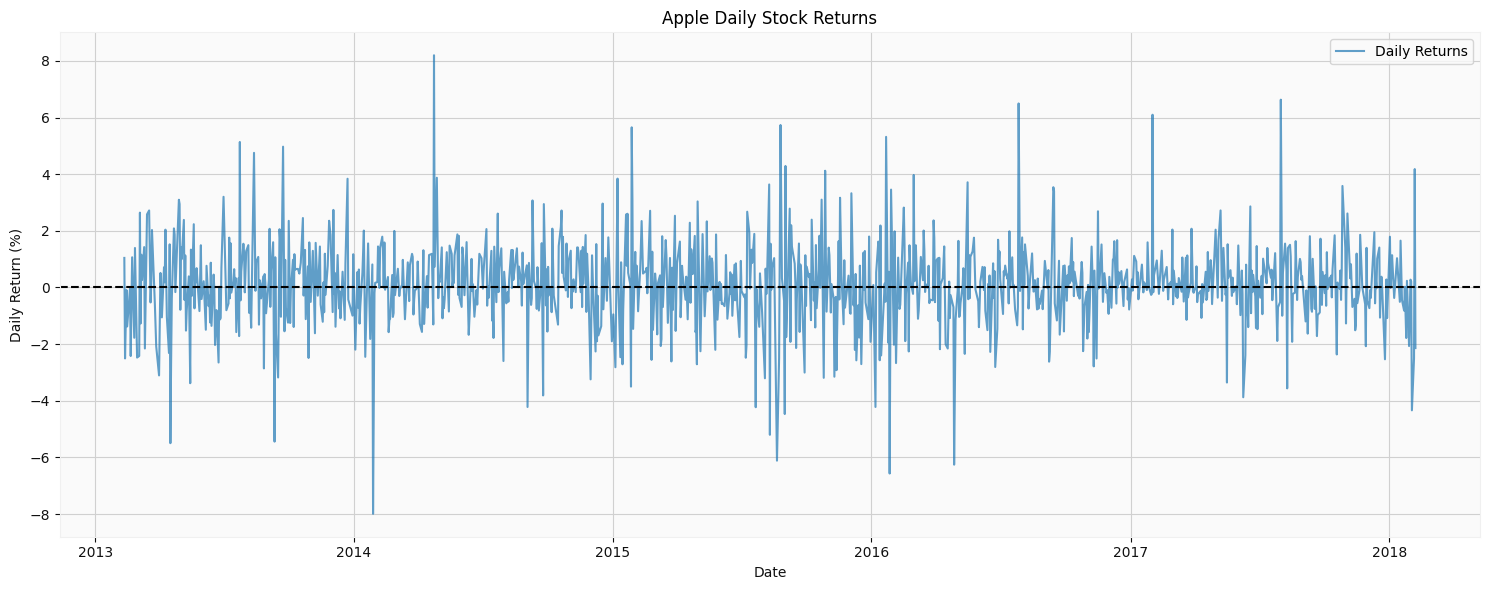

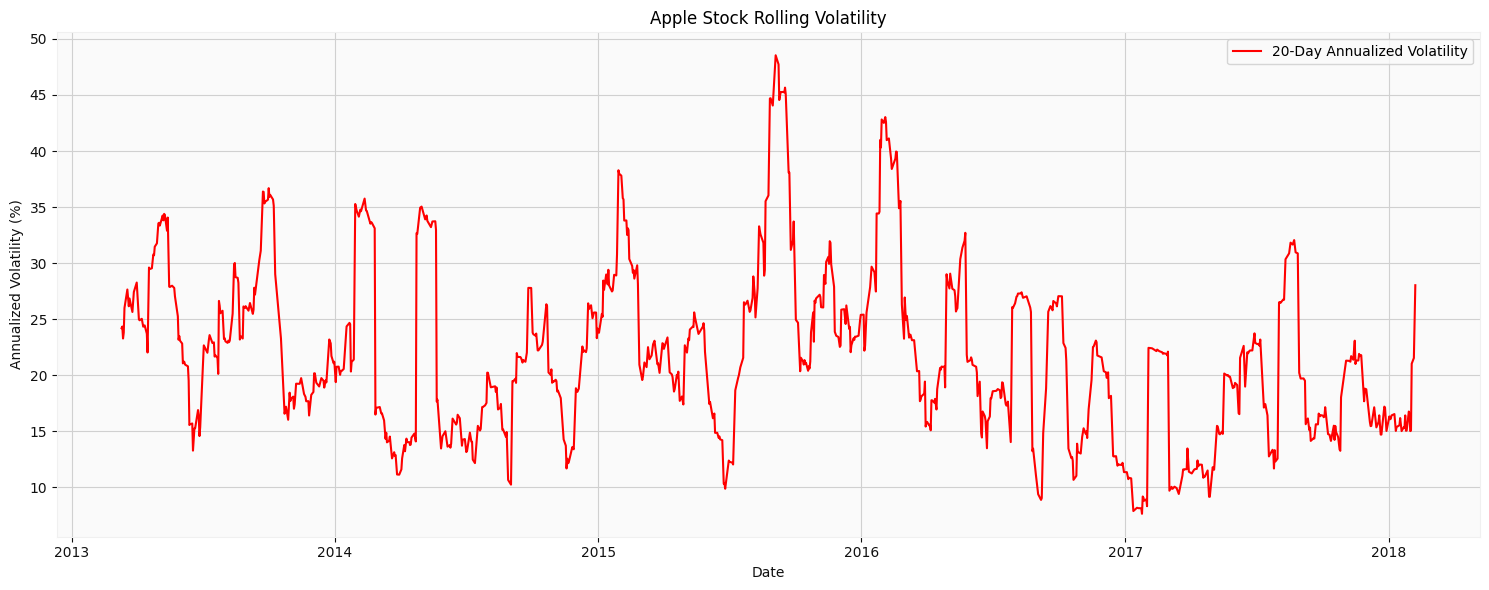

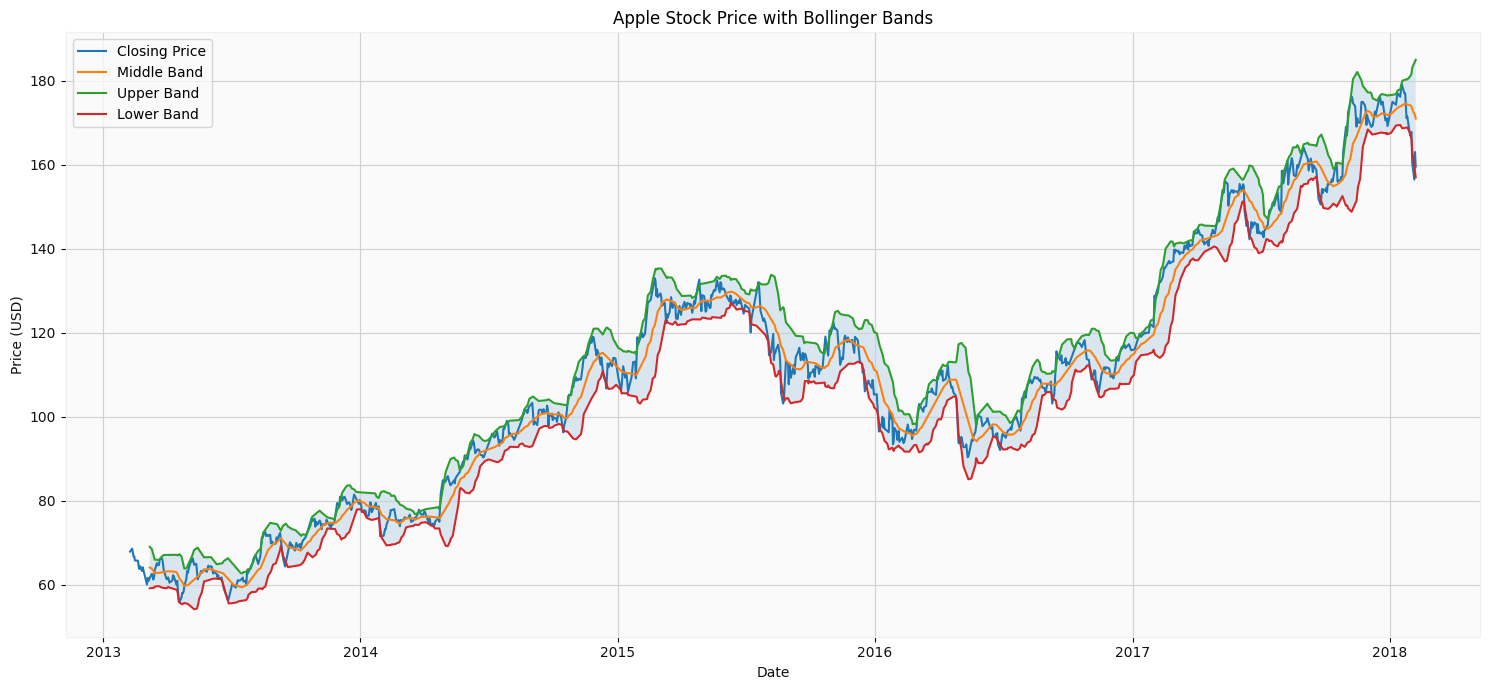

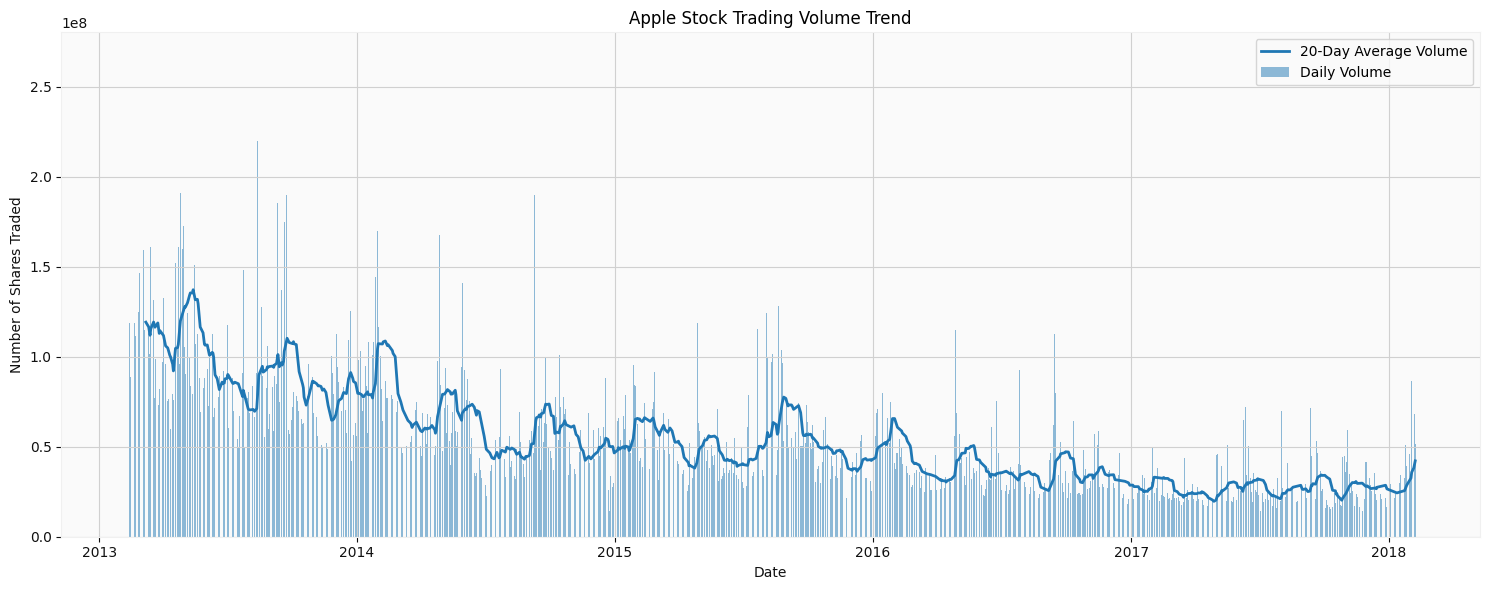

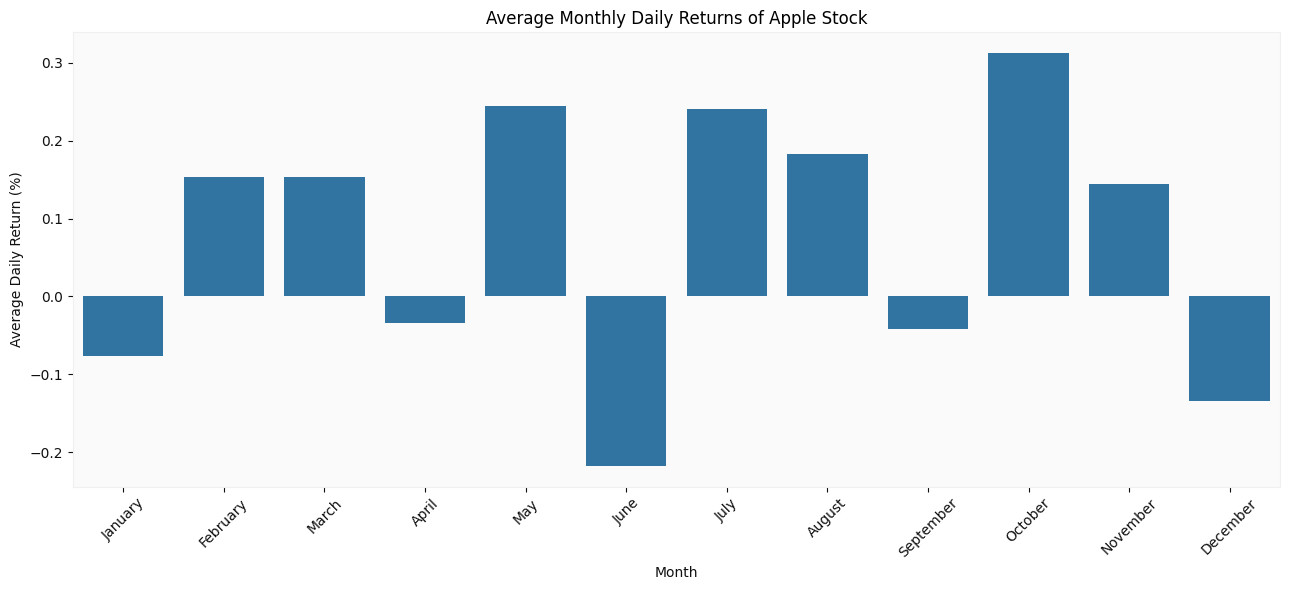

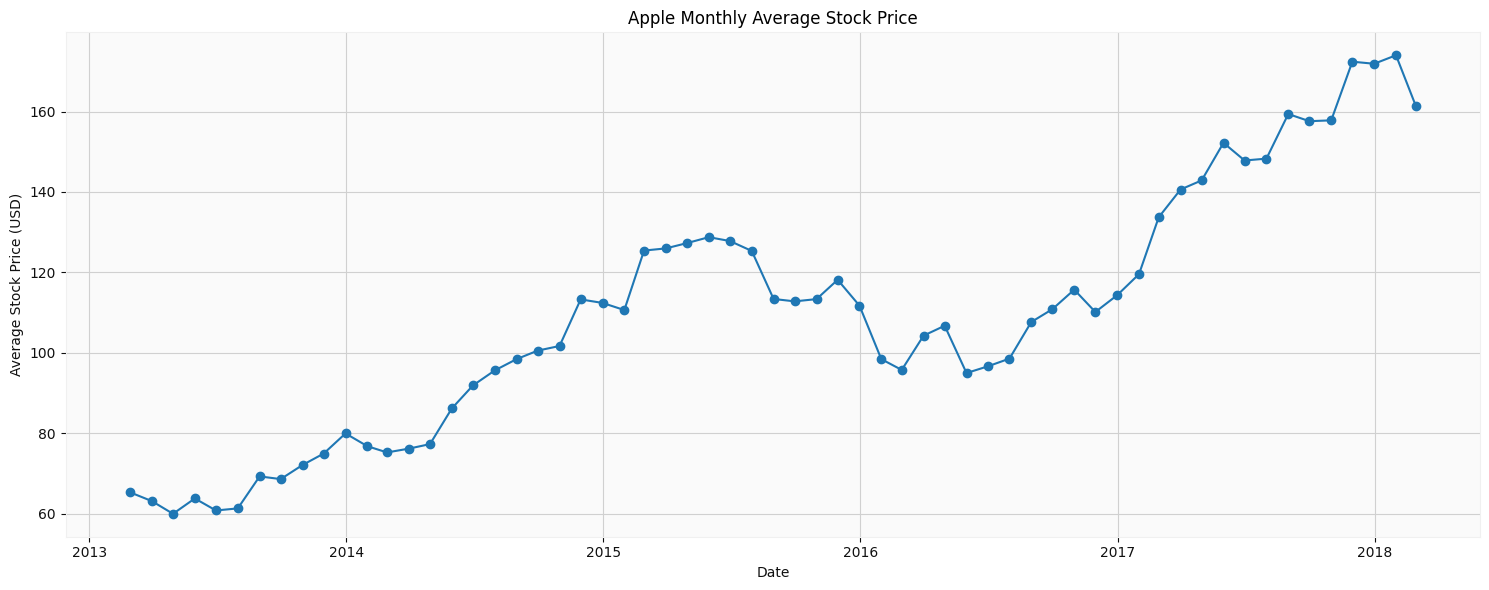


Significant Stock Price Changes:


,close,Daily_Return,volume
date,,,
2013-04-17,57.5428,-5.499299,236138966
2013-07-24,62.9299,5.136019,147978789
2013-08-13,69.9385,4.752298,219634975
2013-09-11,66.8156,-5.444449,224250866
2013-09-23,70.0914,4.969988,190021706
2014-01-28,72.3571,-7.992722,266833581
2014-04-24,81.1099,8.198180,189978082
2015-01-28,115.3100,5.653289,146477063
2015-08-11,113.4900,-5.203809,97082814


Total significant changes: 19


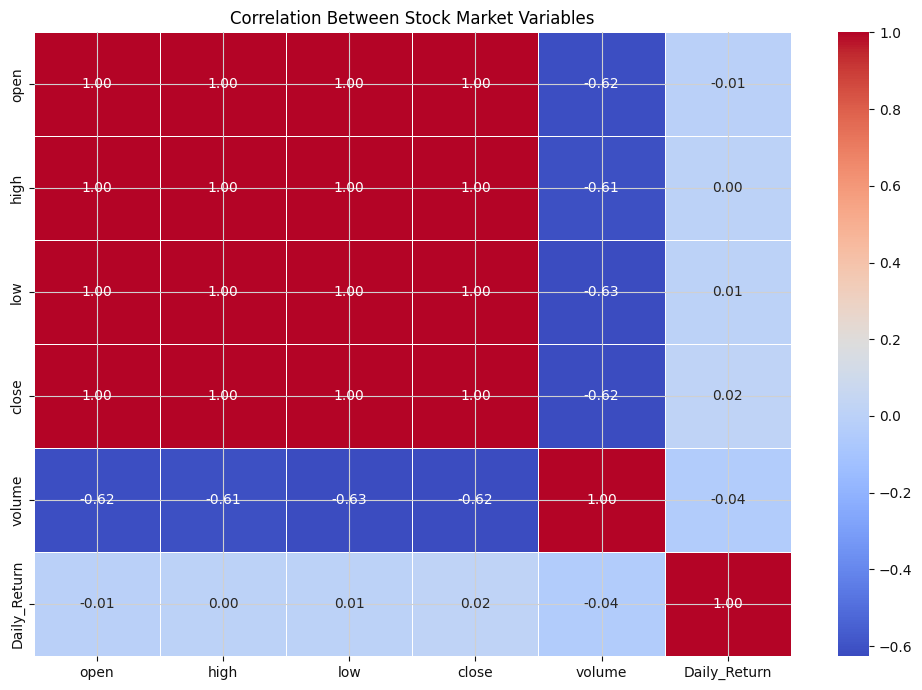

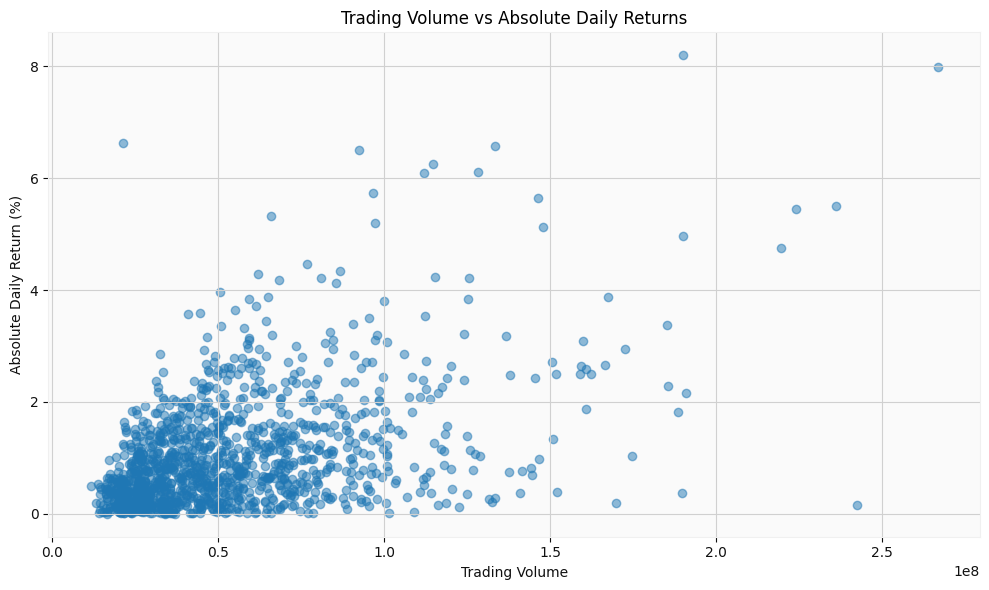


       STOCK MARKET TIME-SERIES ANALYSIS
Company: AAPL
Start Date: 2013-02-08
End Date: 2018-02-07
Total Trading Days: 1259
Average Closing Price: 109.07
Maximum Closing Price: 179.26
Minimum Closing Price: 55.79
Average Daily Return: 0.0786 %
Average Annualized Volatility: 21.79 %
Average Trading Volume: 54047900.0
Significant Price Changes: 19

Monthly Average Daily Returns:
Month
1    -0.076960
2     0.153151
3     0.153665
4    -0.033545
5     0.244397
6    -0.217510
7     0.241298
8     0.183378
9    -0.042262
10    0.312589
11    0.143849
12   -0.134290
Name: Daily_Return, dtype: float64

Analysis Completed Successfully!

Processed dataset saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# ============================================================
# STOCK MARKET TIME-SERIES ANALYSIS USING PYTHON
# Dataset: S&P 500 Stock Market Dataset (Kaggle)
# Company: Apple (AAPL)
# Automatic Dataset Download - Google Colab
# ============================================================

# 1. INSTALL LIBRARIES

!pip install -q kagglehub mplfinance pandas numpy matplotlib seaborn

# 2. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mplfinance as mpf
import kagglehub
import os
import glob

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("deep")

print("Libraries imported successfully!")


# 3. AUTOMATICALLY DOWNLOAD KAGGLE DATASET

print("Downloading S&P 500 dataset from Kaggle...")

dataset_path = kagglehub.dataset_download(
    "camnugent/sandp500"
)

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)


# 4. FIND CSV FILE

csv_files = glob.glob(
    os.path.join(dataset_path, "**", "*.csv"),
    recursive=True
)

matching_files = [
    f for f in csv_files
    if "all_stocks_5yr" in os.path.basename(f).lower()
]

if matching_files:
    csv_path = matching_files[0]
else:
    if not csv_files:
        raise FileNotFoundError("No CSV files found in dataset!")
    csv_path = csv_files[0]

print("Selected CSV:", csv_path)


# 5. LOAD DATASET

df = pd.read_csv(csv_path)

df.columns = df.columns.str.strip().str.lower()

print("\nFirst five rows:")
display(df.head())

print("\nDataset shape:", df.shape)

print("\nDataset information:")
df.info()


# 6. DATA PREPROCESSING

df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

numeric_columns = [
    "open", "high", "low", "close", "volume"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna(
    subset=["date"] + numeric_columns
)

df = df.drop_duplicates()

df = df[
    (df["open"] > 0) &
    (df["high"] > 0) &
    (df["low"] > 0) &
    (df["close"] > 0) &
    (df["volume"] >= 0)
]

df = df.sort_values("date")

print("\nData cleaning completed!")

print("\nMissing values:")
print(df.isnull().sum())


# 7. SELECT COMPANY - APPLE (AAPL)

company = "AAPL"

stock = df[
    df["name"].astype(str).str.upper() == company
].copy()

if stock.empty:
    raise ValueError("AAPL not found in the dataset!")

stock = stock.sort_values("date")

stock = stock.set_index("date")

stock = stock[
    ["open", "high", "low", "close", "volume"]
]

print("\nSelected Company:", company)

print("Total observations:", len(stock))

print("Date range:")
print(stock.index.min(), "to", stock.index.max())

display(stock.head())


# 8. BASIC STOCK PRICE VISUALIZATION

plt.figure(figsize=(14, 6))

plt.plot(
    stock.index,
    stock["close"],
    label="Closing Price"
)

plt.title("Apple Stock Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Stock Price (USD)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 9. CANDLESTICK CHART

mpf.plot(
    stock,
    type="candle",
    style="yahoo",
    title="Apple (AAPL) Candlestick Chart",
    ylabel="Stock Price (USD)",
    volume=True,
    mav=(20, 50),
    figsize=(15, 8),
    tight_layout=True
)


# 10. SIMPLE MOVING AVERAGE (SMA)

stock["SMA_20"] = stock["close"].rolling(20).mean()
stock["SMA_50"] = stock["close"].rolling(50).mean()
stock["SMA_200"] = stock["close"].rolling(200).mean()

plt.figure(figsize=(15, 7))

plt.plot(stock.index, stock["close"],
         label="Closing Price", alpha=0.6)

plt.plot(stock.index, stock["SMA_20"], label="SMA 20")
plt.plot(stock.index, stock["SMA_50"], label="SMA 50")
plt.plot(stock.index, stock["SMA_200"], label="SMA 200")

plt.title("Apple Stock Price with SMA")
plt.xlabel("Date")
plt.ylabel("Price (USD)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 11. EXPONENTIAL MOVING AVERAGE (EMA)

stock["EMA_20"] = stock["close"].ewm(
    span=20, adjust=False
).mean()

stock["EMA_50"] = stock["close"].ewm(
    span=50, adjust=False
).mean()

plt.figure(figsize=(15, 7))

plt.plot(stock.index, stock["close"],
         label="Closing Price", alpha=0.6)

plt.plot(stock.index, stock["EMA_20"], label="EMA 20")
plt.plot(stock.index, stock["EMA_50"], label="EMA 50")

plt.title("Apple Stock Price with EMA")
plt.xlabel("Date")
plt.ylabel("Price (USD)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 12. DAILY RETURNS

stock["Daily_Return"] = (
    stock["close"].pct_change() * 100
)

plt.figure(figsize=(15, 6))

plt.plot(
    stock.index,
    stock["Daily_Return"],
    label="Daily Returns",
    alpha=0.7
)

plt.axhline(0, linestyle="--", color="black")

plt.title("Apple Daily Stock Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 13. ROLLING VOLATILITY

stock["Rolling_Volatility"] = (
    stock["Daily_Return"].rolling(20).std()
)

stock["Annualized_Volatility"] = (
    stock["Rolling_Volatility"] * np.sqrt(252)
)

plt.figure(figsize=(15, 6))

plt.plot(
    stock.index,
    stock["Annualized_Volatility"],
    color="red",
    label="20-Day Annualized Volatility"
)

plt.title("Apple Stock Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility (%)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 14. BOLLINGER BANDS

stock["Middle_Band"] = (
    stock["close"].rolling(20).mean()
)

rolling_std = stock["close"].rolling(20).std()

stock["Upper_Band"] = (
    stock["Middle_Band"] + 2 * rolling_std
)

stock["Lower_Band"] = (
    stock["Middle_Band"] - 2 * rolling_std
)

plt.figure(figsize=(15, 7))

plt.plot(stock.index, stock["close"],
         label="Closing Price")

plt.plot(stock.index, stock["Middle_Band"],
         label="Middle Band")

plt.plot(stock.index, stock["Upper_Band"],
         label="Upper Band")

plt.plot(stock.index, stock["Lower_Band"],
         label="Lower Band")

plt.fill_between(
    stock.index,
    stock["Upper_Band"].to_numpy(),
    stock["Lower_Band"].to_numpy(),
    alpha=0.15
)

plt.title("Apple Stock Price with Bollinger Bands")
plt.xlabel("Date")
plt.ylabel("Price (USD)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 15. TRADING VOLUME TREND

stock["Volume_SMA_20"] = (
    stock["volume"].rolling(20).mean()
)

fig, ax = plt.subplots(figsize=(15, 6))

ax.bar(
    stock.index,
    stock["volume"],
    label="Daily Volume",
    alpha=0.5
)

ax.plot(
    stock.index,
    stock["Volume_SMA_20"],
    label="20-Day Average Volume",
    linewidth=2
)

ax.set_title("Apple Stock Trading Volume Trend")
ax.set_xlabel("Date")
ax.set_ylabel("Number of Shares Traded")

ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()


# 16. SEASONAL PATTERN ANALYSIS

stock["Month"] = stock.index.month

monthly_returns = (
    stock.groupby("Month")["Daily_Return"].mean()
)

month_names = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

plt.figure(figsize=(13, 6))

sns.barplot(
    x=month_names,
    y=monthly_returns.reindex(range(1, 13)).values
)

plt.title("Average Monthly Daily Returns of Apple Stock")
plt.xlabel("Month")
plt.ylabel("Average Daily Return (%)")

plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


# 17. MONTHLY AVERAGE STOCK PRICE

monthly_price = stock["close"].resample("ME").mean()

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_price.index,
    monthly_price.values,
    marker="o"
)

plt.title("Apple Monthly Average Stock Price")
plt.xlabel("Date")
plt.ylabel("Average Stock Price (USD)")

plt.grid(True)
plt.tight_layout()
plt.show()


# 18. IDENTIFY SIGNIFICANT PRICE CHANGES

mean_return = stock["Daily_Return"].mean()
std_return = stock["Daily_Return"].std()

upper_threshold = mean_return + 3 * std_return
lower_threshold = mean_return - 3 * std_return

significant_changes = stock[
    (stock["Daily_Return"] > upper_threshold) |
    (stock["Daily_Return"] < lower_threshold)
]

print("\nSignificant Stock Price Changes:")

display(
    significant_changes[
        ["close", "Daily_Return", "volume"]
    ]
)

print(
    "Total significant changes:",
    len(significant_changes)
)


# 19. CORRELATION ANALYSIS

correlation = stock[
    [
        "open",
        "high",
        "low",
        "close",
        "volume",
        "Daily_Return"
    ]
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Stock Market Variables")

plt.tight_layout()
plt.show()


# 20. PRICE AND VOLUME RELATIONSHIP

plt.figure(figsize=(10, 6))

plt.scatter(
    stock["volume"],
    stock["Daily_Return"].abs(),
    alpha=0.5
)

plt.title("Trading Volume vs Absolute Daily Returns")
plt.xlabel("Trading Volume")
plt.ylabel("Absolute Daily Return (%)")

plt.grid(True)
plt.tight_layout()
plt.show()


# 21. STATISTICAL ANALYSIS SUMMARY

print("\n" + "=" * 55)
print("       STOCK MARKET TIME-SERIES ANALYSIS")
print("=" * 55)

print("Company:", company)

print("Start Date:", stock.index.min().date())
print("End Date:", stock.index.max().date())

print("Total Trading Days:", len(stock))

print(
    "Average Closing Price:",
    round(stock["close"].mean(), 2)
)

print(
    "Maximum Closing Price:",
    round(stock["close"].max(), 2)
)

print(
    "Minimum Closing Price:",
    round(stock["close"].min(), 2)
)

print(
    "Average Daily Return:",
    round(stock["Daily_Return"].mean(), 4), "%"
)

print(
    "Average Annualized Volatility:",
    round(stock["Annualized_Volatility"].mean(), 2), "%"
)

print(
    "Average Trading Volume:",
    round(stock["volume"].mean(), 0)
)

print(
    "Significant Price Changes:",
    len(significant_changes)
)

print("\nMonthly Average Daily Returns:")
print(monthly_returns)

print("\nAnalysis Completed Successfully!")


# 22. EXPORT PROCESSED DATASET

output_file = "/content/Apple_Stock_TimeSeries_Analysis.csv"

stock.to_csv(output_file)

print("\nProcessed dataset saved successfully!")

from google.colab import files
files.download(output_file)

